# Первинний аналіз даних: MRPC (Microsoft Research Paraphrase Corpus)

**Проєкт:** TextProof — реєстрація авторства текстів і виявлення плагіату на основі блокчейну та машинного навчання
**Лабораторна робота:** ЛР1, розділ 3 «Дані для машинного навчання»
**Команда:** Буткевич А. В., Тохтамиш М. С. (ПЗПІ-23-5)

Мета ноутбука — описати набір даних і з'ясувати:

1. Який розмір набору і які в ньому ознаки?
2. Чи є пропуски, дублікати, викиди, дисбаланс класів?
3. Як ознаки пов'язані між собою та з цільовою змінною?
4. Чи не «підглядає» якась ознака в цільову змінну (витік)?
5. Як ділити дані на навчальну, валідаційну й тестову частини і за якими метриками оцінювати моделі?

Під кожним графіком наведено висновок. Рисунки зберігаються в `docs/figures/` під тими самими номерами, що й у звіті.

## 0. Налаштування середовища

Потрібні лише `pandas`, `numpy`, `matplotlib`, `scikit-learn` (див. `ml/requirements.txt`).
Якщо файлів даних немає в `ml/data/raw/`, вони завантажуються автоматично. Сам набір даних у git не комітимо (`.gitignore`), бо ліцензія MSR-SSLA дозволяє поширення лише в некомерційних цілях.

In [1]:
import csv, re, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score, average_precision_score)
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # ноутбук запущено з ml/notebooks/
    ROOT = ROOT.parents[1]
DATA_DIR = ROOT / "ml" / "data" / "raw"
FIG_DIR = ROOT / "docs" / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Палітра: синій — перефразування (1), помаранчевий — не перефразування (0)
C1, C0, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.family": "DejaVu Sans",
    "font.size": 10, "axes.titlesize": 11, "axes.labelcolor": INK,
    "axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, bbox_inches="tight", facecolor="white")
    plt.show()

print("Дані:", DATA_DIR)
print("Рисунки:", FIG_DIR)

Дані: /home/claude/repo/ml/data/raw
Рисунки: /home/claude/repo/docs/figures


## 1. Завантаження даних

**Джерело:** Dolan W. B., Brockett C. *Automatically Constructing a Corpus of Sentential Paraphrases*, IWP 2005; офіційна сторінка — <https://www.microsoft.com/en-us/download/details.aspx?id=52398>. Копія файлів, яку використано тут: репозиторій `wasiahmad/paraphrase_identification` на GitHub.
**Ліцензія:** Microsoft Research Shared Source License Agreement (MSR-SSLA), лише некомерційне використання (навчання, дослідження).
**Зміст:** пари речень із новинних статей; кожну пару двоє анотаторів розмітили як семантично еквівалентну (1) чи ні (0).

Файли мають формат TSV, але всередині речень трапляються лапки, тому читаємо з `quoting=csv.QUOTE_NONE`. Інакше pandas «склеює» рядки і частина пар губиться.

In [2]:
BASE_URL = ("https://raw.githubusercontent.com/wasiahmad/paraphrase_identification/"
            "master/dataset/msr-paraphrase-corpus/")
FILES = {"train": "msr_paraphrase_train.txt", "test": "msr_paraphrase_test.txt"}

def load_split(split):
    path = DATA_DIR / FILES[split]
    if not path.exists():
        print(f"Завантажую {FILES[split]} ...")
        urllib.request.urlretrieve(BASE_URL + FILES[split], path)
    df = pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, encoding="utf-8-sig",
                     dtype={"#1 String": str, "#2 String": str})
    df = df.rename(columns={"Quality": "label", "#1 ID": "id1", "#2 ID": "id2",
                            "#1 String": "s1", "#2 String": "s2"})
    df["split"] = split
    return df

train_raw, test_raw = load_split("train"), load_split("test")
df = pd.concat([train_raw, test_raw], ignore_index=True)

print(f"Train: {len(train_raw)} пар, test: {len(test_raw)} пар, разом: {len(df)}")
print(f"Унікальних речень: {pd.concat([df.s1, df.s2]).nunique()}")
display(df.head())

Train: 4076 пар, test: 1725 пар, разом: 5801
Унікальних речень: 10944


,label,id1,id2,s1,s2,split
0,1,702876,702977,"Amrozi accused his brother, whom he called ""the witness"", of deliberately distorting his evidence.","Referring to him as only ""the witness"", Amrozi accused his brother of deliberately distorting his evidence.",train
1,0,2108705,2108831,Yucaipa owned Dominick's before selling the chain to Safeway in 1998 for $2.5 billion.,Yucaipa bought Dominick's in 1995 for $693 million and sold it to Safeway for $1.8 billion in 1998.,train
2,1,1330381,1330521,"They had published an advertisement on the Internet on June 10, offering the cargo for sale, he added.","On June 10, the ship's owners had published an advertisement on the Internet, offering the explosives for sale.",train
3,0,3344667,3344648,"Around 0335 GMT, Tab shares were up 19 cents, or 4.4%, at A$4.56, having earlier set a record high of A$4.57.","Tab shares jumped 20 cents, or 4.6%, to set a record closing high at A$4.57.",train
4,1,1236820,1236712,"The stock rose $2.11, or about 11 percent, to close Friday at $21.51 on the New York Stock Exchange.",PG&E Corp. shares jumped $1.63 or 8 percent to $21.03 on the New York Stock Exchange on Friday.,train


## 2. Словник ознак

Сирі дані містять лише ідентифікатори, два речення і мітку. Для аналізу та базового методу обчислюємо з кожної пари числові ознаки. Ті самі ознаки рахуватиме оракул TextProof для поданого тексту й оригіналу.

| Ознака | Тип | Опис |
|---|---|---|
| `label` | бінарна (ціль) | 1 — перефразування, 0 — ні |
| `id1`, `id2` | ціле | ідентифікатори речень у корпусі (службові) |
| `s1`, `s2` | рядок | тексти речень |
| `len1_w`, `len2_w` | ціле | довжина речень у словах |
| `len_diff_w` | ціле | \|len1_w − len2_w\| |
| `len_ratio` | дійсне [0;1] | min(len)/max(len) |
| `jaccard` | дійсне [0;1] | коефіцієнт Жаккара множин слів (формула 4 звіту) |
| `tfidf_cos` | дійсне [0;1] | косинус TF-IDF-векторів (формули 2–3), словник навчено лише на train |
| `num_mismatch` | бінарна | у реченнях є числа, і їхні множини не збігаються |
| `id_gap` | ціле | \|id2 − id1\|, службова ознака для перевірки витоку |

In [3]:
TOKEN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
NUM = re.compile(r"\d+(?:[.,]\d+)?")

def tokens(s):
    return TOKEN.findall(s.lower())

def jaccard(a, b):
    A, B = set(tokens(a)), set(tokens(b))
    return len(A & B) / len(A | B) if A | B else 0.0

def num_mismatch(a, b):
    na, nb = set(NUM.findall(a)), set(NUM.findall(b))
    return int(bool(na or nb) and na != nb)

df["len1_w"] = df.s1.map(lambda s: len(tokens(s)))
df["len2_w"] = df.s2.map(lambda s: len(tokens(s)))
df["len_diff_w"] = (df.len1_w - df.len2_w).abs()
df["len_ratio"] = df[["len1_w", "len2_w"]].min(axis=1) / df[["len1_w", "len2_w"]].max(axis=1)
df["jaccard"] = [jaccard(a, b) for a, b in zip(df.s1, df.s2)]
df["num_mismatch"] = [num_mismatch(a, b) for a, b in zip(df.s1, df.s2)]
df["id_gap"] = (df.id2 - df.id1).abs()

# TF-IDF навчаємо ТІЛЬКИ на train, щоб статистика тесту не потрапила в ознаку
is_tr = df.split == "train"
tfidf = TfidfVectorizer(lowercase=True, token_pattern=r"[a-z0-9]+(?:'[a-z]+)?")
tfidf.fit(pd.concat([df.loc[is_tr, "s1"], df.loc[is_tr, "s2"]]))
V1, V2 = tfidf.transform(df.s1), tfidf.transform(df.s2)
df["tfidf_cos"] = np.asarray(V1.multiply(V2).sum(axis=1)).ravel()  # вектори L2-нормовані

FEATURES = ["len1_w", "len2_w", "len_diff_w", "len_ratio", "jaccard",
            "tfidf_cos", "num_mismatch", "id_gap"]
print("Розмір словника TF-IDF:", len(tfidf.vocabulary_))
display(df[FEATURES + ["label"]].describe().T.round(3))

Розмір словника TF-IDF: 13603


,count,mean,std,min,25%,50%,75%,max
len1_w,5801.0,19.513,5.253,6.000,16.000,19.000,24.000,35.0
len2_w,5801.0,19.460,5.250,5.000,16.000,19.000,23.000,34.0
len_diff_w,5801.0,3.178,2.299,0.000,1.000,3.000,5.000,14.0
len_ratio,5801.0,0.850,0.100,0.542,0.773,0.857,0.933,1.0
jaccard,5801.0,0.515,0.167,0.100,0.381,0.500,0.640,1.0
tfidf_cos,5801.0,0.652,0.169,0.098,0.535,0.668,0.784,1.0
num_mismatch,5801.0,0.261,0.439,0.000,0.000,0.000,1.000,1.0
id_gap,5801.0,127.817,125.562,1.000,40.000,86.000,173.000,1255.0
label,5801.0,0.672,0.469,0.000,0.000,1.000,1.000,1.0


## 3. Пропуски та якість даних

Пропуски за стовпцями:
label    0
id1      0
id2      0
s1       0
s2       0


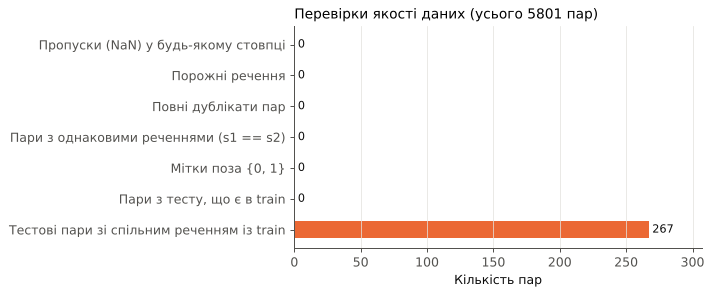

In [4]:
checks = {
    "Пропуски (NaN) у будь-якому стовпці": int(df[["label", "id1", "id2", "s1", "s2"]].isna().any(axis=1).sum()),
    "Порожні речення": int(((df.s1.str.strip() == "") | (df.s2.str.strip() == "")).sum()),
    "Повні дублікати пар": int(df.duplicated(["s1", "s2"]).sum()),
    "Пари з однаковими реченнями (s1 == s2)": int((df.s1 == df.s2).sum()),
    "Мітки поза {0, 1}": int((~df.label.isin([0, 1])).sum()),
    "Пари з тесту, що є в train": int(test_raw.set_index(["id1", "id2"]).index
                                       .isin(train_raw.set_index(["id1", "id2"]).index).sum()),
    "Тестові пари зі спільним реченням із train": int(
        (test_raw.s1.isin(set(train_raw.s1) | set(train_raw.s2)) |
         test_raw.s2.isin(set(train_raw.s1) | set(train_raw.s2))).sum()),
}
na_by_col = df[["label", "id1", "id2", "s1", "s2"]].isna().sum()
print("Пропуски за стовпцями:"); print(na_by_col.to_string())

fig, ax = plt.subplots(figsize=(8, 3.4))
names, vals = list(checks)[::-1], list(checks.values())[::-1]
ax.barh(names, vals, color=[C0 if v else C1 for v in vals], height=0.55)
for i, v in enumerate(vals):
    ax.text(v + max(vals) * 0.01, i, str(v), va="center", color=INK, fontsize=9)
ax.set_xlim(0, max(10, max(vals) * 1.15))
ax.set_xlabel("Кількість пар")
ax.set_title(f"Перевірки якості даних (усього {len(df)} пар)", loc="left")
ax.grid(axis="y", visible=False)
savefig(fig, "fig3_1_quality.png")

**Рисунок 3.1. Висновок.** Пропусків, порожніх речень, некоректних міток і дублікатів пар немає, тож імпутація й очищення не потрібні. Жодна тестова пара не повторює навчальну. Проте 267 тестових пар (15,5 %) містять речення, яке трапляється і в train: корпус зібрано з кластерів новин, і одне речення входить у кілька пар. Прямим витоком мітки це не є, але модель, що «запам'ятовує» речення, може отримати завищені оцінки. Тому метрики додатково рахуватимемо на «чистій» частині тесту (розділ 9). Технічна пастка формату: без `QUOTE_NONE` частина рядків губиться через лапки в тексті.

## 4. Баланс класів

label,0,1,0 %,1 %
split,,,,
train,1323,2753,32.5,67.5
test,578,1147,33.5,66.5


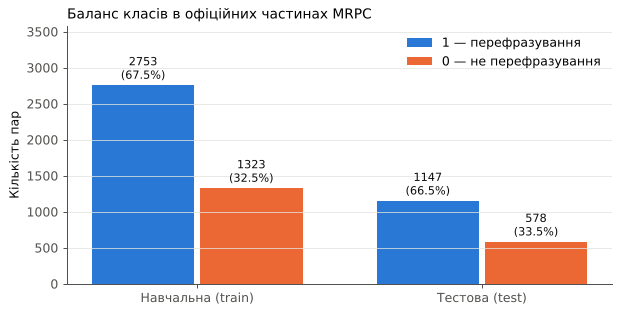

Тривіальний класифікатор «завжди 1» на test: accuracy=0.665, F1=0.799, precision=0.665, recall=1.000


In [5]:
bal = df.groupby(["split", "label"]).size().unstack().loc[["train", "test"]]
share = bal.div(bal.sum(axis=1), axis=0)
display(pd.concat([bal, (share * 100).round(1).add_suffix(" %")], axis=1))

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(2); w = 0.36
for k, (lab, col, name) in enumerate([(1, C1, "1 — перефразування"), (0, C0, "0 — не перефразування")]):
    b = ax.bar(x + (k - 0.5) * (w + 0.02), bal[lab], w, color=col, label=name)
    for rect, n, p in zip(b, bal[lab], share[lab]):
        ax.text(rect.get_x() + rect.get_width() / 2, n + 40, f"{n}\n({p:.1%})",
                ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(x, ["Навчальна (train)", "Тестова (test)"])
ax.set_ylabel("Кількість пар"); ax.set_ylim(0, bal.values.max() * 1.3)
ax.set_title("Баланс класів в офіційних частинах MRPC", loc="left")
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
savefig(fig, "fig3_2_balance.png")

maj = share.loc["test", 1]
print(f"Тривіальний класифікатор «завжди 1» на test: accuracy={maj:.3f}, "
      f"F1={2*maj/(1+maj):.3f}, precision={maj:.3f}, recall=1.000")

**Рисунок 3.2. Висновок.** Дисбаланс помірний: 67,5 % / 32,5 % у train і 66,5 % / 33,5 % у test, тобто частини стратифіковані однаково. Наслідок для метрик: модель, яка завжди відповідає «1», уже має accuracy 0,665 і F1 = 0,799. Тому accuracy не годиться як основна метрика, а цільове F1 ≥ 0,85 (НФВ2) лише на ~5 п. п. вище за тривіальний рівень. Звітуватимемо також precision, recall і PR-AUC та порівнюватимемо з тривіальною базою. Пересемплінг не потрібен; при виділенні валідації застосовуємо стратифікацію.

## 5. Розподіли довжин речень

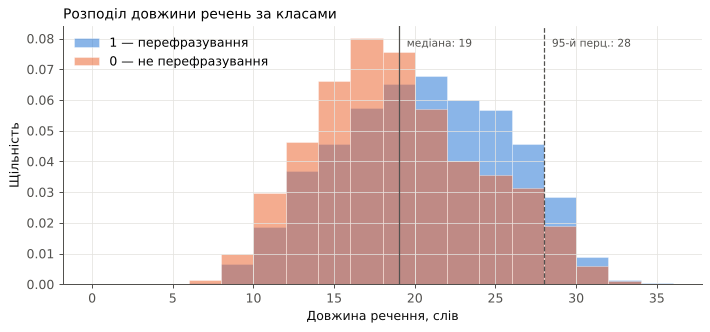

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,3802.0,18.4,5.1,5.0,15.0,18.0,22.0,33.0
1,7800.0,20.0,5.2,6.0,16.0,20.0,24.0,35.0


In [6]:
long = pd.DataFrame({
    "len": np.r_[df.len1_w, df.len2_w],
    "label": np.r_[df.label, df.label],
})
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0, long.len.max() + 2, 2)
for lab, col, name in [(1, C1, "1 — перефразування"), (0, C0, "0 — не перефразування")]:
    ax.hist(long.loc[long.label == lab, "len"], bins=bins, density=True, alpha=0.55,
            color=col, label=name, edgecolor="white", linewidth=0.5)
for q, ls in [(0.5, "-"), (0.95, "--")]:
    v = long.len.quantile(q)
    ax.axvline(v, color=MUTED, ls=ls, lw=1)
    ax.text(v + 0.5, ax.get_ylim()[1] * 0.92, f"{'медіана' if q == .5 else '95-й перц.'}: {v:.0f}",
            color=MUTED, fontsize=8.5)
ax.set_xlabel("Довжина речення, слів"); ax.set_ylabel("Щільність")
ax.set_title("Розподіл довжини речень за класами", loc="left"); ax.legend()
savefig(fig, "fig3_3_length.png")
display(long.groupby("label").len.describe().round(1))

**Рисунок 3.3. Висновок.** Речення короткі: медіана 19 слів, 95 % речень не довші за 28 слів, діапазон 5–35. Розподіли класів сильно перекриваються. Перефразування трохи довші (медіана 20 проти 18 слів), але окремо довжина класів не розділяє. Звідси головне обмеження набору: TextProof перевірятиме документи на сотні й тисячі слів (НФВ3 — до 2000 слів), а MRPC навчає моделі лише на рівні речень. У ЛР2 документи розбиватимемо на речення або вікна по 20–40 слів і агрегуватимемо оцінки, а для перевірки на довгих текстах додамо корпус PAN.

## 6. Викиди

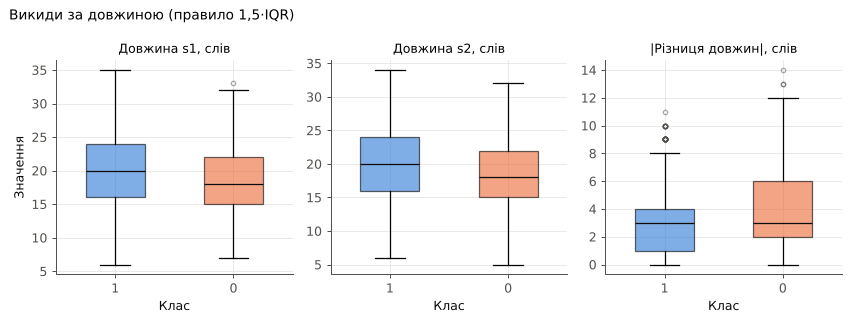

,ознака,межі IQR,викидів,"частка, %"
0,len1_w,[4.0; 36.0],0,0.00
1,len2_w,[5.5; 33.5],3,0.05
2,len_diff_w,[-5.0; 11.0],6,0.10


,label,len1_w,len2_w,s1,s2
5727,0,17,31,"Oran Smith, president of the Palmetto Family Council, said the assassination marked the end of America's innocence.","Oran Smith, president of the Palmetto Family Council, said the assassination marked the end of America’s innocence, giving way to the if-it-feels-good-do-it 1960s and ’70s."
5265,0,18,31,"The soldiers, from the 3rd Armored Cavalry, were hurt when their Humvee vehicle struck a mine in Hit.",The pipeline exploded only a few hours after two U.S. soldiers from the 3rd Armored Cavalry were wounded when their Humvee vehicle detonated a land mine in the same area.
4894,0,29,16,"The Dow Jones Industrial Average fell 0.7 per cent to 9,547.43 while the S&P 500 was 0.8 per cent weaker at 1,025.79.","The Dow Jones industrial average <.DJI> fell 44 points, or 0.46 percent, to 9,568."


In [7]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

cols = [("len1_w", "Довжина s1, слів"), ("len2_w", "Довжина s2, слів"),
        ("len_diff_w", "|Різниця довжин|, слів")]
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.6))
rows = []
for ax, (c, title) in zip(axes, cols):
    data = [df.loc[df.label == 1, c], df.loc[df.label == 0, c]]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True,
                    flierprops=dict(marker="o", markersize=3.5, alpha=0.5, markeredgecolor=MUTED),
                    medianprops=dict(color=INK))
    for patch, col in zip(bp["boxes"], [C1, C0]):
        patch.set_facecolor(col); patch.set_alpha(0.6)
    ax.set_xticks([1, 2], ["1", "0"]); ax.set_xlabel("Клас"); ax.set_title(title, fontsize=10)
    n, lo, hi = iqr_outliers(df[c])
    rows.append({"ознака": c, "межі IQR": f"[{lo:.1f}; {hi:.1f}]", "викидів": n,
                 "частка, %": round(100 * n / len(df), 2)})
axes[0].set_ylabel("Значення")
fig.suptitle("Викиди за довжиною (правило 1,5·IQR)", x=0.01, ha="left", fontsize=11)
savefig(fig, "fig3_4_outliers.png")
out_tab = pd.DataFrame(rows); display(out_tab)

top = df.sort_values("len_diff_w", ascending=False).head(3)[["label", "len1_w", "len2_w", "s1", "s2"]]
display(top)

**Рисунок 3.4. Висновок.** Викидів практично немає: за правилом 1,5·IQR це 0 пар за довжиною s1, 3 пари (0,05 %) за довжиною s2 і 6 пар (0,1 %) за різницею довжин. Корпус уже відфільтровано авторами за довжиною. Найбільші різниці довжин (12–14 слів) трапляються лише в парах класу 0: одне речення містить додаткову інформацію, якої немає в іншому (приклади у виводі вище). Це не помилки розмітки, а корисний сигнал, тому нічого не видаляємо. Для класу 0 медіана різниці довжин та сама (3 слова), але розкид більший (Q3 = 6 проти 4).

## 7. Лексичний перетин за класами (Жаккар і TF-IDF)

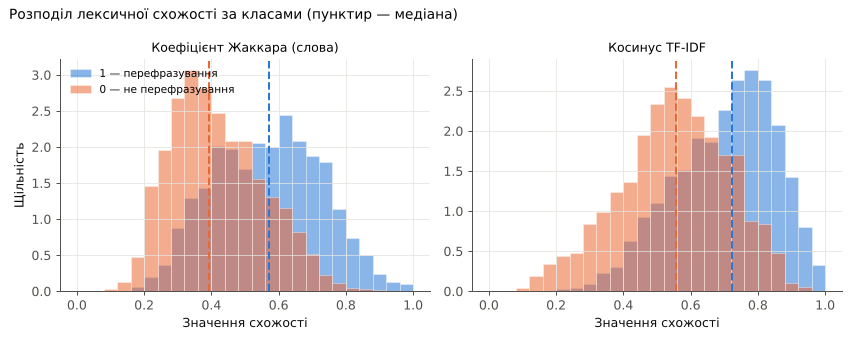

jaccard        tfidf_cos       
         mean median      mean median
label                                
0       0.415  0.393     0.551  0.556
1       0.564  0.571     0.701  0.722

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=False)
bins = np.linspace(0, 1, 26)
for ax, (c, title) in zip(axes, [("jaccard", "Коефіцієнт Жаккара (слова)"),
                                 ("tfidf_cos", "Косинус TF-IDF")]):
    for lab, col, name in [(1, C1, "1 — перефразування"), (0, C0, "0 — не перефразування")]:
        v = df.loc[df.label == lab, c]
        ax.hist(v, bins=bins, density=True, alpha=0.55, color=col, label=name,
                edgecolor="white", linewidth=0.5)
        ax.axvline(v.median(), color=col, lw=1.6, ls="--")
    ax.set_title(title, fontsize=10); ax.set_xlabel("Значення схожості")
axes[0].set_ylabel("Щільність"); axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Розподіл лексичної схожості за класами (пунктир — медіана)", x=0.01, ha="left", fontsize=11)
savefig(fig, "fig3_5_similarity.png")
display(df.groupby("label")[["jaccard", "tfidf_cos"]].agg(["mean", "median"]).round(3))

**Рисунок 3.5. Висновок.** Перефразування в середньому мають вищий лексичний перетин (медіана Жаккара 0,57 проти 0,39, косинуса TF-IDF 0,72 проти 0,56), але розподіли класів сильно перекриваються. У діапазоні Жаккара 0,35–0,6 трапляються пари обох класів: неперефразування зі спільними словами (змінено число, суб'єкт) і перефразування зі значною синонімічною заміною. Отже, лексичні міри відрізняють класи лише частково. Це обґрунтовує вибір TF-IDF як базового методу і семантичної моделі MPNet як моделі другого рівня (розділ 2.1).

## 8. Кореляційна матриця

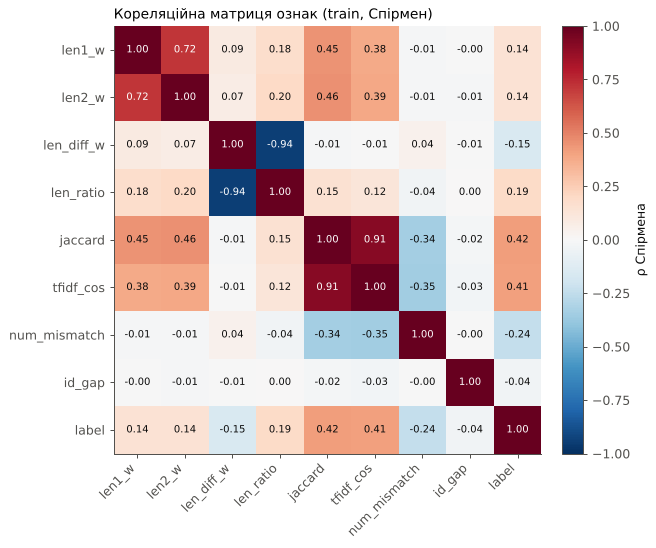

,ρ з label
jaccard,0.419
tfidf_cos,0.410
num_mismatch,-0.238
len_ratio,0.192
len_diff_w,-0.150
len2_w,0.144
len1_w,0.143
id_gap,-0.035


In [9]:
corr_cols = ["len1_w", "len2_w", "len_diff_w", "len_ratio", "jaccard",
             "tfidf_cos", "num_mismatch", "id_gap", "label"]
corr = df.loc[df.split == "train", corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else INK)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("ρ Спірмена")
ax.set_title("Кореляційна матриця ознак (train, Спірмен)", loc="left")
savefig(fig, "fig3_6_corr.png")
display(corr["label"].drop("label").sort_values(key=abs, ascending=False).round(3).to_frame("ρ з label"))

**Рисунок 3.6. Висновок.** Сильно корельовані пари ознак: `jaccard` і `tfidf_cos` (ρ = 0,91), `len_diff_w` і `len_ratio` (ρ = −0,94), `len1_w` і `len2_w` (ρ = 0,72). Ознаки в перших двох парах майже дублюють одна одну, тож для лінійної моделі з кожної пари досить однієї. Інакше мультиколінеарність зробить коефіцієнти нестабільними. З міткою найсильніше пов'язані лексичні міри (ρ = 0,42 і 0,41) і `num_mismatch` (ρ = −0,24): розбіжність чисел знижує ймовірність перефразування. Жодна ознака не корелює з міткою сильніше за |ρ| = 0,5, тобто задача нетривіальна і явної «підказки» в даних немає. Службова `id_gap` з міткою не пов'язана (ρ = −0,04).

## 9. Перевірка витоку цільової змінної

Витік — це ознака, яка містить інформацію про мітку, недоступну в момент прогнозу в реальній системі. Перевіряємо три речі:

1. **ROC-AUC кожної ознаки окремо.** AUC > 0,95 для однієї ознаки є підозрілим.
2. **Службові ідентифікатори** (`id_gap`): у реальній системі їх немає, тож вони не повинні нести сигнал.
3. **Перетин речень між train і test**: однакові речення в обох частинах завищать тестові метрики.

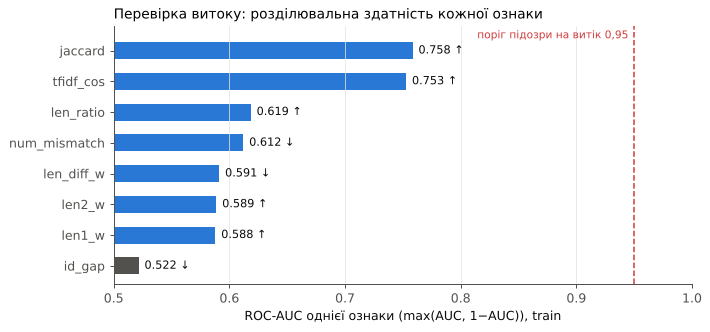

,ознака,AUC,напрям
4,jaccard,0.758,↑
5,tfidf_cos,0.753,↑
3,len_ratio,0.619,↑
6,num_mismatch,0.612,↓
2,len_diff_w,0.591,↓
1,len2_w,0.589,↑
0,len1_w,0.588,↑
7,id_gap,0.522,↓


Речень у train: 7816, у test: 3393, спільних: 265 (7.81% тестових речень)
Тестових пар зі спільним реченням: 267 (15.5%), з обома спільними реченнями: 5


,пар,частка класу 1
has_shared,,
False,1458,0.678
True,267,0.596


In [10]:
tr = df[df.split == "train"]
auc_rows = []
for c in FEATURES:
    auc = roc_auc_score(tr.label, tr[c])
    auc_rows.append((c, max(auc, 1 - auc), "↑" if auc >= 0.5 else "↓"))
auc_df = pd.DataFrame(auc_rows, columns=["ознака", "AUC", "напрям"]).sort_values("AUC")

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [MUTED if c == "id_gap" else C1 for c in auc_df["ознака"]]
ax.barh(auc_df["ознака"], auc_df["AUC"] - 0.5, left=0.5, color=colors, height=0.55)
for i, (a, d) in enumerate(zip(auc_df["AUC"], auc_df["напрям"])):
    ax.text(a + 0.005, i, f"{a:.3f} {d}", va="center", fontsize=9, color=INK)
ax.axvline(0.95, color="#d03b3b", ls="--", lw=1.2)
ax.text(0.945, len(auc_df) - 0.6, "поріг підозри на витік 0,95", color="#d03b3b", fontsize=8.5, ha="right")
ax.set_ylim(-0.6, len(auc_df) - 0.2)
ax.set_xlim(0.5, 1.0); ax.set_xlabel("ROC-AUC однієї ознаки (max(AUC, 1−AUC)), train")
ax.set_title("Перевірка витоку: розділювальна здатність кожної ознаки", loc="left")
ax.grid(axis="y", visible=False)
savefig(fig, "fig3_7_leakage.png")
display(auc_df.sort_values("AUC", ascending=False).round(3))

s_tr = set(train_raw.s1) | set(train_raw.s2)
s_te = set(test_raw.s1) | set(test_raw.s2)
shared = s_tr & s_te
print(f"Речень у train: {len(s_tr)}, у test: {len(s_te)}, спільних: {len(shared)} "
      f"({len(shared)/len(s_te):.2%} тестових речень)")

# Скільки тестових ПАР зачіпає цей перетин і чи пов'язаний він із міткою
te = test_raw.copy()
te["has_shared"] = te.s1.isin(shared) | te.s2.isin(shared)
te["both_shared"] = te.s1.isin(shared) & te.s2.isin(shared)
print(f"Тестових пар зі спільним реченням: {te.has_shared.sum()} ({te.has_shared.mean():.1%}), "
      f"з обома спільними реченнями: {te.both_shared.sum()}")
display(te.groupby("has_shared").label.agg(["size", "mean"]).round(3)
          .rename(columns={"size": "пар", "mean": "частка класу 1"}))

**Рисунок 3.7. Висновок.** Найсильніші окремі ознаки (`jaccard` і `tfidf_cos`) дають AUC 0,76 і 0,75, тобто набагато менше за поріг підозри 0,95. Службова `id_gap` має AUC 0,52, отже нумерація речень мітку не видає. Витоку цільової змінної в ознаках не виявлено. Перетин на рівні речень існує: 265 речень (7,8 % тестових) і 267 тестових пар (15,5 %). У цих парах частка класу 1 нижча (59,6 % проти 67,8 %), тож вони, навпаки, складніші. Для чесного порівняння моделей у ЛР4 метрики звітуватимемо і на повному тесті, і на «чистих» 1458 парах без спільних речень. Окремо зазначимо: `tfidf_cos` навчено лише на train. Якби словник IDF будувався на всьому корпусі, статистика тесту потрапила б в ознаку — цю помилку закриває конвеєр `fit` тільки на train.

## 10. Числа в реченнях як ознака

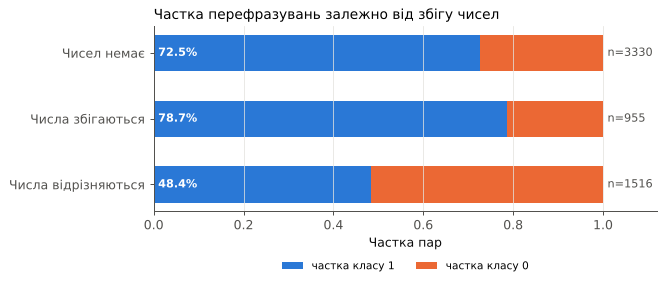

,size,mean
grp,,
Чисел немає,3330,0.725
Числа збігаються,955,0.787
Числа відрізняються,1516,0.484


In [11]:
has_num = df.s1.str.contains(r"\d") | df.s2.str.contains(r"\d")
grp = np.select([~has_num, df.num_mismatch == 0, df.num_mismatch == 1],
                ["Чисел немає", "Числа збігаються", "Числа відрізняються"], default="")
tab = (pd.DataFrame({"grp": grp, "label": df.label})
       .groupby("grp").label.agg(["size", "mean"])
       .reindex(["Чисел немає", "Числа збігаються", "Числа відрізняються"]))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(tab.index[::-1], tab["mean"][::-1], color=C1, height=0.55, label="частка класу 1")
ax.barh(tab.index[::-1], 1 - tab["mean"][::-1], left=tab["mean"][::-1], color=C0, height=0.55,
        label="частка класу 0")
for i, (m, n) in enumerate(zip(tab["mean"][::-1], tab["size"][::-1])):
    ax.text(0.01, i, f"{m:.1%}", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(1.01, i, f"n={n}", va="center", color=MUTED, fontsize=9)
ax.set_xlim(0, 1.12); ax.set_xlabel("Частка пар")
ax.set_title("Частка перефразувань залежно від збігу чисел", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8.5)
ax.grid(axis="y", visible=False)
savefig(fig, "fig3_8_numbers.png")
display(tab.round(3))

**Рисунок 3.8. Висновок.** Якщо числа в реченнях відрізняються, частка перефразувань падає до 48,4 % проти 78,7 % для пар зі збіжними числами і 72,5 % для пар без чисел. Розбіжність чисел трапляється часто, у 26 % пар (1516 з 5801). Для системи виявлення плагіату це важливо: заміна дати чи суми зберігає лексичний перетин, але змінює зміст. Трансформерні моделі погано чутливі до чисел, тому ознаку `num_mismatch` залишимо в агрегованому звіті оракула як додатковий сигнал для арбітра.

## 11. Схема поділу даних

- **Test:** офіційна тестова частина MRPC (1725 пар). Використовується **один раз** — для фінального порівняння в ЛР4.
- **Train / validation:** офіційну навчальну частину (4076 пар) ділимо стратифіковано 90/10 (`random_state=42`). На validation підбираємо поріг τ (формула 6) для кожного методу окремо, бо розподіли схожості різні.
- **Крос-валідація:** для оцінки стабільності порогу — стратифікована 5-кратна CV на train (у ЛР3).
- Векторизатор TF-IDF, масштабування і будь-які статистики навчаються тільки на train-частині.

Ця схема зберігає порівнянність із літературою, де звітують результати на офіційному test MRPC [3].

In [12]:
train_df = df[df.split == "train"].reset_index(drop=True)
test_df = df[df.split == "test"].reset_index(drop=True)
tr_df, val_df = train_test_split(train_df, test_size=0.10, stratify=train_df.label,
                                 random_state=SEED)
split_tab = pd.DataFrame({
    "частина": ["train", "validation", "test"],
    "пар": [len(tr_df), len(val_df), len(test_df)],
    "клас 1": [tr_df.label.sum(), val_df.label.sum(), test_df.label.sum()],
    "клас 0": [(1 - tr_df.label).sum(), (1 - val_df.label).sum(), (1 - test_df.label).sum()],
})
split_tab["частка 1, %"] = (100 * split_tab["клас 1"] / split_tab["пар"]).round(1)
display(split_tab)

,частина,пар,клас 1,клас 0,"частка 1, %"
0,train,3668,2477,1191,67.5
1,validation,408,276,132,67.6
2,test,1725,1147,578,66.5


## 12. Метрики та контрольна перевірка базового методу

**Основна метрика — F1 для класу 1** (НФВ2: ≥ 0,85). Вона враховує і пропущені перефразування (recall), і хибні звинувачення (precision), і не завищується через дисбаланс так, як accuracy.

Додаткові метрики:
- **Precision і Recall** окремо: для системи плагіату хибне звинувачення (FP) дорожче за пропуск, бо запускає спір.
- **FPR на парах класу 0** — пряма перевірка НФВ6 (≤ 5 %).
- **ROC-AUC і PR-AUC** — якість ранжування незалежно від порогу.
- **Accuracy** — лише для порівняння з літературою [3].

Нижче — контрольний прогін базового методу (TF-IDF + косинус із порогом τ), щоб зафіксувати відправну точку для ЛР2.

In [13]:
def evaluate(y, score, tau, name):
    pred = (score >= tau).astype(int)
    neg = y == 0
    return {"метод": name, "τ": round(tau, 3),
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "FPR (клас 0)": pred[neg].mean(),
            "ROC-AUC": roc_auc_score(y, score) if np.ptp(score) > 0 else 0.5,
            "PR-AUC": average_precision_score(y, score)}

grid = np.linspace(0.05, 0.95, 181)
f1_val = [f1_score(val_df.label, (val_df.tfidf_cos >= t).astype(int)) for t in grid]
tau_f1 = grid[int(np.argmax(f1_val))]
# поріг під НФВ6: мінімальний τ, за якого FPR на validation ≤ 5 %
fpr_val = np.array([(val_df.tfidf_cos[val_df.label == 0] >= t).mean() for t in grid])
tau_fpr = grid[np.argmax(fpr_val <= 0.05)]

y = test_df.label.values
res = pd.DataFrame([
    evaluate(y, np.ones(len(y)), 0.5, "Тривіальний «завжди 1»"),
    evaluate(y, test_df.tfidf_cos.values, tau_f1, "TF-IDF, τ за max F1 (val)"),
    evaluate(y, test_df.tfidf_cos.values, tau_fpr, "TF-IDF, τ за FPR ≤ 5 % (val)"),
]).round(3)
train_sents = set(train_df.s1) | set(train_df.s2)
clean = ~(test_df.s1.isin(train_sents) | test_df.s2.isin(train_sents))
res = pd.concat([res, pd.DataFrame([evaluate(y[clean.values], test_df.tfidf_cos.values[clean.values],
                 tau_f1, f"TF-IDF, τ за max F1, «чистий» test (n={clean.sum()})")]).round(3)],
                ignore_index=True)
display(res)

,метод,τ,Accuracy,Precision,Recall,F1,FPR (клас 0),ROC-AUC,PR-AUC
0,Тривіальний «завжди 1»,0.50,0.665,0.665,1.000,0.799,1.000,0.500,0.665
1,"TF-IDF, τ за max F1 (val)",0.42,0.715,0.711,0.964,0.818,0.779,0.746,0.848
2,"TF-IDF, τ за FPR ≤ 5 % (val)",0.78,0.541,0.875,0.361,0.511,0.102,0.746,0.848
3,"TF-IDF, τ за max F1, «чистий» test (n=1458)",0.42,0.719,0.718,0.966,0.823,0.798,0.740,0.854


**Висновок щодо метрик.** Базовий метод із порогом за максимумом F1 (τ = 0,42) лише трохи перевершує тривіальний класифікатор (F1 0,818 проти 0,799). Поріг опускається низько, і майже всі пари стають «плагіатом»: recall 0,96, але FPR 0,78. Якщо поріг вибрати під НФВ6 (τ = 0,78, FPR ≤ 5 % на validation), на тесті FPR виходить уже 10,2 %, а recall падає до 0,36 (F1 0,51). Отже, поріг, підібраний на 408 парах валідації, переноситься на тест нестабільно, і лексичний базовий метод **не може одночасно** виконати НФВ2 і НФВ6. Це очікуваний результат, і він кількісно обґрунтовує потребу в семантичній моделі другого рівня. У ЛР3–4 порівнюватимемо моделі за F1 і за recall при фіксованому FPR = 5 %.

## 13. Підсумок

| Питання | Відповідь |
|---|---|
| Розмір | 5801 пара (train 4076, test 1725), 10 944 унікальних речень |
| Ознаки | 2 тексти, 2 id, мітка; 8 обчислених числових ознак |
| Пропуски / дублікати | немає |
| Викиди | ≤ 0,1 % за правилом 1,5·IQR; залишаємо |
| Дисбаланс | 67/33, помірний → F1, стратифікація, порівняння з тривіальною базою |
| Зв'язки | `jaccard`↔`tfidf_cos` ρ = 0,91, `len_diff_w`↔`len_ratio` ρ = −0,94; з міткою максимум ρ = 0,42 |
| Витік | в ознаках не виявлено (max AUC 0,76, `id_gap` 0,52); 15,5 % тестових пар мають спільне речення з train → окрема оцінка на «чистому» тесті |
| Поділ | офіційний test + стратифікований 90/10 train/val, seed 42 |
| Метрики | F1 (основна), Precision, Recall, FPR, ROC-AUC, PR-AUC |
| Базовий рівень | «завжди 1»: F1 0,799; TF-IDF: F1 0,818, але FPR 0,78 |
| Головне обмеження | рівень речень (медіана 19 слів) проти документів системи → вікна + PAN у ЛР2 |

In [14]:
df.to_csv(DATA_DIR.parent / "mrpc_features.csv", index=False)
res.to_csv(FIG_DIR / "baseline_metrics.csv", index=False)
print("Збережено:", DATA_DIR.parent / "mrpc_features.csv")
print("Рисунки:", sorted(p.name for p in FIG_DIR.glob("fig3_*.png")))

Збережено: /home/claude/repo/ml/data/mrpc_features.csv
Рисунки: ['fig3_1_quality.png', 'fig3_2_balance.png', 'fig3_3_length.png', 'fig3_4_outliers.png', 'fig3_5_similarity.png', 'fig3_6_corr.png', 'fig3_7_leakage.png', 'fig3_8_numbers.png']
